BIBLIOTECAS

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Preprocesamiento de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Algoritmos de clasificacion
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


# metricas de clasificacion
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report


PREPROCESADO DE DATOS

In [3]:
df = pd.read_csv('train.csv')
display(df)

print('Dimensiones:', df.shape)
print('\nTipos de datos:')
print(df.dtypes)
print('\nValores nulos por columna:')
print(df.isna().sum())
print('\nFilas duplicadas:', df.duplicated().sum())
print('\nResumen de la variable objetivo :')
print(df['satisfaction'].describe())

df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103899,103899,94171,Female,disloyal Customer,23,Business travel,Eco,192,2,1,...,2,3,1,4,2,3,2,3,0.0,neutral or dissatisfied
103900,103900,73097,Male,Loyal Customer,49,Business travel,Business,2347,4,4,...,5,5,5,5,5,5,4,0,0.0,satisfied
103901,103901,68825,Male,disloyal Customer,30,Business travel,Business,1995,1,1,...,4,3,2,4,5,5,4,7,14.0,neutral or dissatisfied
103902,103902,54173,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,...,1,4,5,1,5,4,1,0,0.0,neutral or dissatisfied


Dimensiones: (103904, 25)

Tipos de datos:
Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness 

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [4]:
# Borrar columnas que no nos digan nada
# df = df.drop("columna_a_borrar",axis=1)
df = df.drop("id",axis=1)
df = df.drop("Unnamed: 0",axis=1)

# Variables predictoras y variable objetivo
X = df.drop('satisfaction', axis=1)
y = df['satisfaction']


# Columnas numéricas y categóricas
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(exclude=['object']).columns

# median = mediana ; mean = media

# Pipelines para preprocesamiento
# primero los NaN les pones la mediana
# después los escalas(media 0) desviación típica 1
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),      
    ('scaler', StandardScaler())                        
])


# si a una fila le falta algo le pones 'most_frequent'
# OHE , min_frequency=20 (tiene que haber al menos 20 para que se cree una columna), 
#  sino lo agrupa en una nueva que se llama 'nombre_columna_infrequent_if_exist'
# ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20)) 
# si quieres que ignore algo:
# ('onehot', OneHotEncoder(handle_unknown='ignore')) 
# para que haga todo:
# ('onehot', OneHotEncoder(sparse_output=False))   
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False))   
])

# Combinamos los transformadores en un ColumnTransformer
# habla entre las cols y los transformadores y lo combina
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# Dividimos el dataset en entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Muestras para entrenar: {X_train.shape[0]}')
print(f'Muestras para validar: {X_test.shape[0]}')
print(f'Número de variables numéricas: {len(num_cols)}')
print(f'Número de variables categóricas: {len(cat_cols)}')

Muestras para entrenar: 83123
Muestras para validar: 20781
Número de variables numéricas: 18
Número de variables categóricas: 4


In [5]:

# Para que la salida de de tipo DataFrame y no de tipo NumpyArray y se pueda dibujar
# hay que poner tambien en el constructor sparse_output = False
preprocessor.set_output(transform="pandas")

# Procesa las columnas(numericas y categóricas)
# fit_transformed = aprende las medias y medianas y aplica
# transform = solo aplica con lo que ya has aprendido
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print('Forma del conjunto de entrenamiento tras el preprocesado:', X_train_transformed.shape)
print('Forma del conjunto de prueba tras el preprocesado:', X_test_transformed.shape)
print('Número total de variables generadas:', len(preprocessor.get_feature_names_out()))

feature_names = preprocessor.get_feature_names_out()
print('\nPrimeras 15 variables transformadas:')
print(feature_names[:15])

Forma del conjunto de entrenamiento tras el preprocesado: (83123, 27)
Forma del conjunto de prueba tras el preprocesado: (20781, 27)
Número total de variables generadas: 27

Primeras 15 variables transformadas:
['num__Age' 'num__Flight Distance' 'num__Inflight wifi service'
 'num__Departure/Arrival time convenient' 'num__Ease of Online booking'
 'num__Gate location' 'num__Food and drink' 'num__Online boarding'
 'num__Seat comfort' 'num__Inflight entertainment' 'num__On-board service'
 'num__Leg room service' 'num__Baggage handling' 'num__Checkin service'
 'num__Inflight service']


CLASIFICACIÓN

DECISION TREE

In [6]:
from sklearn.tree import DecisionTreeClassifier

depth = []
accDT = []

for i in range(1,20):
    decision_tree = DecisionTreeClassifier(random_state=0, max_depth=i)
    # Entrenar modelo
    decision_tree.fit(X_train_transformed, y_train)
    # Hacer prediccion
    dt_pred = decision_tree.predict(X_test_transformed)
    # Accuracy
    dt_accuracy = accuracy_score(y_test, dt_pred)
    print("max_depth ",i,"Acc ",dt_accuracy)
    depth.append(i)
    accDT.append(dt_accuracy)
    
dt_accuracyMax = np.argmax(accDT)
print("Accuracy ",accDT[dt_accuracyMax], " with max_depth ",depth[dt_accuracyMax])

decision_tree = DecisionTreeClassifier(random_state=0, max_depth=depth[dt_accuracyMax])
decision_tree.fit(X_train_transformed, y_train)

max_depth  1 Acc  0.7869688657908667
max_depth  2 Acc  0.8604013281362783
max_depth  3 Acc  0.8845580097204176
max_depth  4 Acc  0.8895625812039845
max_depth  5 Acc  0.9042875703767865
max_depth  6 Acc  0.9186757133920408
max_depth  7 Acc  0.929935999230066
max_depth  8 Acc  0.9360473509455753
max_depth  9 Acc  0.9407150762715942
max_depth  10 Acc  0.9447091092825177
max_depth  11 Acc  0.9480294499783456
max_depth  12 Acc  0.9521678456282181
max_depth  13 Acc  0.9534671093787594
max_depth  14 Acc  0.954285164332804
max_depth  15 Acc  0.9541889225735046
max_depth  16 Acc  0.9539001972956066
max_depth  17 Acc  0.9529859005822626
max_depth  18 Acc  0.952937779702613
max_depth  19 Acc  0.951734757711371
Accuracy  0.954285164332804  with max_depth  14


,criterion,'gini'
,splitter,'best'
,max_depth,14
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


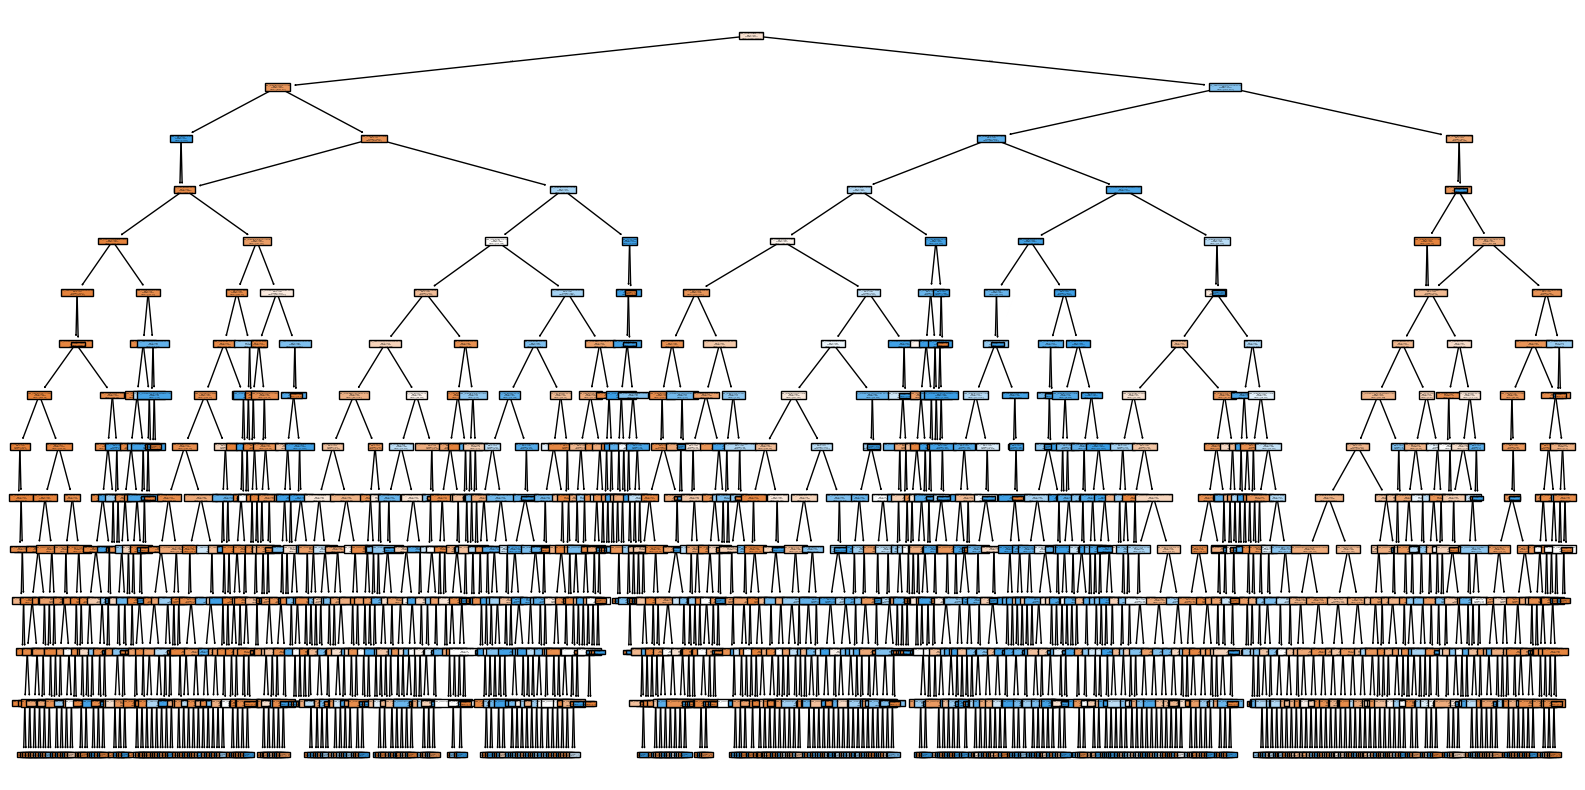

In [7]:
# figura de 20 x 10
plt.figure(figsize=(20,10))
# construirlo
plot_tree(decision_tree, feature_names=X_train_transformed.columns, filled=True)
plt.show()

El mejor arboles de decisiones: 


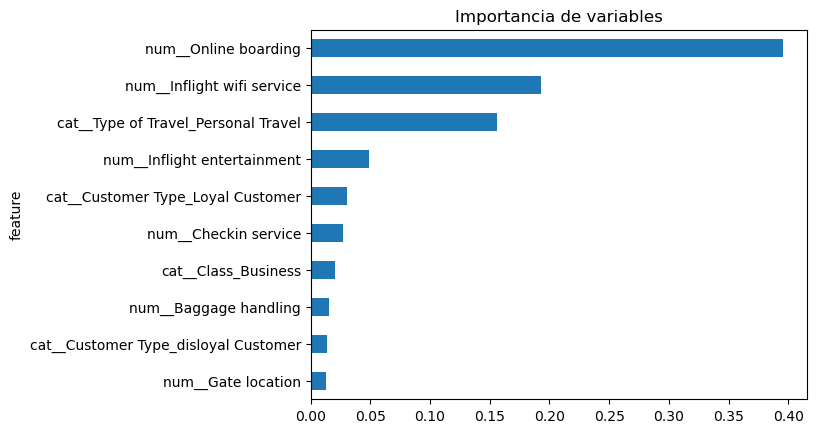

In [8]:
importancias = decision_tree.feature_importances_

df_importancias = pd.DataFrame({
    'feature': X_train_transformed.columns,
    'importance': importancias
}).sort_values(by='importance', ascending=False)

# print(df_importancias)

# Se queda solamente con las 10 primeras filas (el top 10 de las más importantes)
# kind= barh es que sea de barras
# x = features es decirle donde va el eje
# legend = False es para que nos oculte la leyenda (solamente hay un color)
df_importancias.head(10).plot(
    kind='barh', x='feature', y='importance', legend=False
)
# Si no el top 1 estaría abajo del todo
plt.gca().invert_yaxis()
plt.title("Importancia de variables")
print("El mejor arboles de decisiones: ")
plt.show()

RANDOM FOREST

In [9]:

# n_estimators = número de árboles de decisiones
rfClass = RandomForestClassifier(n_estimators=20,max_depth=9, random_state=0) # construir
rfClass.fit(X_train_transformed, y_train)               # entrenar
y_predictRF = rfClass.predict(X_test_transformed)       # predecir

rf_accuracy = accuracy_score(y_test, y_predictRF)
print("accuracy",rf_accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_predictRF))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_predictRF))

accuracy 0.9431692411337279

Classification Report:
                          precision    recall  f1-score   support

neutral or dissatisfied       0.94      0.96      0.95     11713
              satisfied       0.94      0.93      0.93      9068

               accuracy                           0.94     20781
              macro avg       0.94      0.94      0.94     20781
           weighted avg       0.94      0.94      0.94     20781

Confusion Matrix:
 [[11210   503]
 [  678  8390]]


KNN

In [10]:
from sklearn.neighbors import KNeighborsClassifier

ks = []                     # las k
acc = []                    # la accuaricy de cada k
knnPredictions = []         # las predicciones de cada k

# Probar k E [1, 20]
for i in range(1,4):
    
    # n_neighbors = la k del momento , metric = la metrica que quieras usar
    neigh = KNeighborsClassifier(n_neighbors=i, metric="manhattan")
    neigh.fit(X_train_transformed, y_train)                                 # entreno
    y_predictKNN = neigh.predict(X_test_transformed)                        # prediccion
    knn_accuracy = accuracy_score(y_test, y_predictKNN)         # accuaracy

    knnPredictions.append(y_predictKNN)
    ks.append(i)
    acc.append(knn_accuracy)
    print("K ",i,knn_accuracy)

knnAccuracyMax = np.argmax(acc)
print("Accuracy ",acc[knnAccuracyMax], " with K ",ks[knnAccuracyMax])

K  1 0.9204080650594293
K  2 0.9231990760791108
K  3 0.9337856696020403
Accuracy  0.9337856696020403  with K  3


MVP

In [11]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Tamaño de X_train:", X_train_transformed.shape)
print("Tamaño de y_train:", y_train.shape)

# constructor
mlp = MLPClassifier(
    hidden_layer_sizes=(30, 10), # Dos capas ocultas con 30 y 10 neuronas
    activation='relu',           # Función no lineal
    max_iter=7000,               # Límite de épocas de estudio
    alpha=0.01,                  # Regularización (evita el sobreajuste)
    learning_rate_init=0.001,    # Velocidad de aprendizaje
    random_state=0               # Semilla para que el resultado sea siempre el mismo
)

# entrenar
print("\nEntrenando la red neuronal...")
mlp.fit(X_train_transformed, y_train)

# predecir
print("Haciendo la predicción a los datos...")
y_pred = mlp.predict(X_test_transformed)

# resultados
accuracy = accuracy_score(y_test, y_pred)

print("\n=== RESULTADOS DEL MODELO ===")
print("Accauricy: ", accuracy)
print(f"Accuracy (Porcentaje de acierto): {accuracy * 100:.2f}%\n")

print("Matriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

Tamaño de X_train: (83123, 27)
Tamaño de y_train: (83123,)

Entrenando la red neuronal...
Haciendo la predicción a los datos...

=== RESULTADOS DEL MODELO ===
Accauricy:  0.9570761753524855
Accuracy (Porcentaje de acierto): 95.71%

Matriz de Confusión:
[[11467   246]
 [  646  8422]]


SVM SIMPLE

In [ ]:
# Support Vector Classification


# Crear y entrenar una SVM simple
# kernel .= tipo de kernel
# C .= parámetro de regularización(cuánto le debe importar los errores) ; 1 es lo normal
# random_state .= semilla
svm_simple = SVC(kernel='linear', C=1.0, random_state=13)

svm_simple.fit(X_train_transformed, y_train)

# Predicciones
y_pred_svm_simple = svm_simple.predict(X_test_transformed)

# Accuracy
accuracy_svm_simple = accuracy_score(y_test, y_pred_svm_simple)
print(f"\nSVM lineal Accuracy: {accuracy_svm_simple * 100:.2f}%")

# Métricas
print("\nClassification Report (SVM lineal):\n")
print(classification_report(y_test, y_pred_svm_simple))

print("\nMatriz de Confusión (SVM lineal):\n")
print(confusion_matrix(y_test, y_pred_svm_simple))

SVM NO LINEAL

In [ ]:

# Crear y entrenar el modelo SVM
# al no decir el tipo de kernel, por defecto usa el 'rbf' que es no linear
svm = SVC(random_state=13)
# svm = SVC(C=1.0, kernel='rbf', gamma='scale', random_state=13)

# OJO: Usamos X_train_transformed y X_test_transformed generados en el paso 5.1
svm.fit(X_train_transformed, y_train)

# Hacer predicciones con el modelo SVM
y_pred_svm = svm.predict(X_test_transformed)

# Evaluar el modelo SVM
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"\nSVM Accuracy: {accuracy_svm * 100:.2f}%")

# Reportes detallados
print("\nClassification Report (SVM):\n", classification_report(y_test, y_pred_svm))
print("\nMatriz de Confusión (SVM):\n", confusion_matrix(y_test, y_pred_svm))